In [3]:
import xmlrpc.client as xml
import os
import csv
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
import traceback
import math
import sys
import time

proxy = xml.ServerProxy("http://localhost:1080/RPC2")
plecs = proxy.plecs
directory = r"C:\Users\Goat_\Documents\Research\Class E\\"
model = "derated compression"
plecs.load(directory + model + ".plecs")

datadir = directory + model + "/freq_sweep_derated/"
os.makedirs(datadir, exist_ok=True)

In [4]:
def get_data(file):
    data = pd.read_csv(directory + file)
    return data

In [5]:
def round_sig(x, sig=4):
    if x == 0:
        return 0.0
    return round(x, sig - int(math.floor(math.log10(abs(x)))) - 1)

In [17]:
freq = np.linspace(800e3, 1200e3, num=21, endpoint=True)
print("Freq:", freq)

loads = np.array([0, 0.5, 1, 1.5, 2, 3, 5, 10, 20, 10e3])
print("Loads:", loads)

Freq: [ 800000.  820000.  840000.  860000.  880000.  900000.  920000.  940000.
  960000.  980000. 1000000. 1020000. 1040000. 1060000. 1080000. 1100000.
 1120000. 1140000. 1160000. 1180000. 1200000.]
Loads: [0.0e+00 5.0e-01 1.0e+00 1.5e+00 2.0e+00 3.0e+00 5.0e+00 1.0e+01 2.0e+01
 1.0e+04]


In [26]:
filename = datadir + "3VIN_4TURN_freq_sweep_data.csv"
if not os.path.exists(filename):
    with open(filename, "w", newline="") as f:
        writer = csv.writer(f)
        write_to_csv = ["kOhm", "kHz", "IIN", "PIN", "IRMS", "VRMS", "POUT", "EFF", "ZVS"]
        writer.writerow(write_to_csv)

In [27]:
curr_time = time.time()

for l in loads:
    for f in freq:
        opts = {'ModelVars' : { 
            'rtest' : float(l),
            'freq' : float(f),
            'phasem' : -1.0,
            'phasep' : 1.0
        } }
        
        try:
            results = plecs.simulate(model, opts)

            IIN = round_sig(results['Values'][2][-1], 4)
            PIN = round_sig(results['Values'][3][-1], 4)
            IRMS = round_sig(results['Values'][4][-1], 4)
            VRMS = round_sig(results['Values'][5][-1], 4)
            POUT = round_sig(results['Values'][6][-1], 4)
            EFF = round_sig(results['Values'][7][-1], 4)
            ZVS = round_sig(min(results['Values'][8][-200:]), 4)
        except Exception as e:
            IIN = 1e-9
            PIN = 1e-9
            IRMS = 1e-9
            VRMS = 1e-9
            POUT = 1e-9
            EFF = 1e-9
            ZVS = 1e-9

        elapsed = int(time.time() - curr_time)

        print(
            f"\rElapsed: {elapsed} F: {f/1e3:.1f} kHz, R: {l/1e3:.1f} kOhm  IIN: {IIN} PIN: {PIN} IRMS: {IRMS} VRMS: {VRMS} POUT: {POUT} EFF: {EFF} ZVS: {ZVS}",
            end="",
            flush=True
        )
        
        with open(filename, "a", newline="") as csvfile:
            writer = csv.writer(csvfile)
            write_to_csv = [l, f, IIN, PIN, IRMS, VRMS, POUT, EFF, ZVS]
            writer.writerow(write_to_csv)

print("Simulations Finished")

Elapsed: 1433 F: 1200.0 kHz, R: 10.0 kOhm  IIN: 5.949 PIN: 17.93 IRMS: 0.002846 VRMS: 14.23 POUT: 0.0405 EFF: 0.002259 ZVS: -7.496Simulations Finished


# PLOTTING

## Efficiency

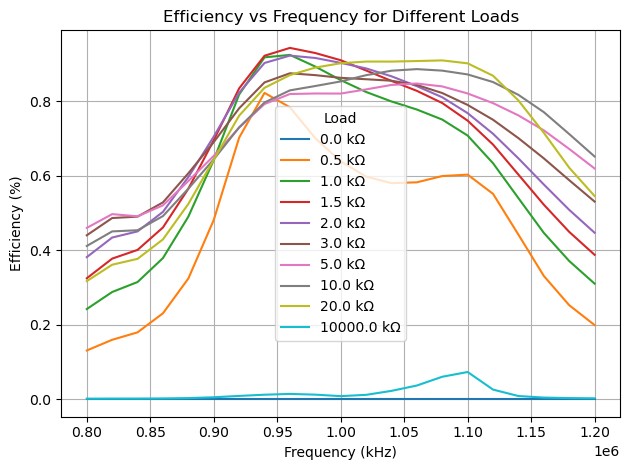

In [28]:
import pandas as pd
import matplotlib.pyplot as plt

# Load CSV
df = pd.read_csv(filename)

# Loop through unique loads
for load in df['kOhm'].unique():
    subset = df[df['kOhm'] == load]  # Filter by load
    plt.plot(subset['kHz'], subset['EFF'], label=f'{load} kΩ')

# Labels and title
plt.xlabel('Frequency (kHz)')
plt.ylabel('Efficiency (%)')
plt.title('Efficiency vs Frequency for Different Loads')
plt.grid(True)
plt.legend(title='Load')
plt.tight_layout()
plt.show()


## VOUT

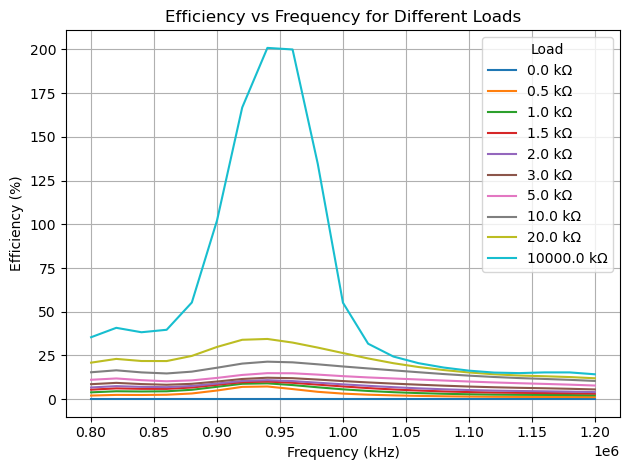

In [32]:
import pandas as pd
import matplotlib.pyplot as plt

# Load CSV
df = pd.read_csv(filename)

# Loop through unique loads
for load in df['kOhm'].unique():
    subset = df[df['kOhm'] == load]  # Filter by load
    plt.plot(subset['kHz'], subset['VRMS'], label=f'{load} kΩ')

# Labels and title
plt.xlabel('Frequency (kHz)')
plt.ylabel('VRMS (V)')
plt.title('VRMS vs Frequency for Different Loads')
plt.grid(True)
plt.legend(title='Load')
plt.tight_layout()
plt.show()


## PIN

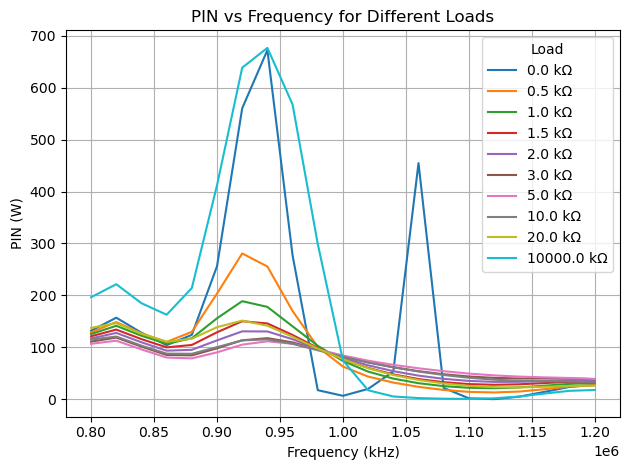

In [33]:
import pandas as pd
import matplotlib.pyplot as plt

# Load CSV
df = pd.read_csv(filename)

# Loop through unique loads
for load in df['kOhm'].unique():
    subset = df[df['kOhm'] == load]  # Filter by load
    plt.plot(subset['kHz'], subset['PIN'], label=f'{load} kΩ')

# Labels and title
plt.xlabel('Frequency (kHz)')
plt.ylabel('PIN (W)')
plt.title('PIN vs Frequency for Different Loads')
plt.grid(True)
plt.legend(title='Load')
plt.tight_layout()
plt.show()
